# Plotting the Results

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/ch4/4C-butadiene/butadiene_plots.ipynb)
:::

We have data from a [previous rotation scan](ch4C-B-butadiene.ipynb#rotational-scan-text) for butadiene. Depending on the level of theory and the Z-matrix used, we generated several data files. You may have used different file names, but these are the files in the data folder for this notebook.

``` text
butadiene_scan_HF_631.json
butadiene_scan_B3LYP-D3BJ_631GX.json
butadiene_scan_HF_631-nosym.json
butadiene_scan_B3LYP-D3BJ_631GX-nosym.json
butadiene_scan_HF_631-C2.json
butadiene_scan_B3LYP-D3BJ_631GX-C2.json
```

## Setting up this Notebook

The collapsed [code cell below](#setup-cell-butadiene-plots) will **load in** all the *Python* packages and set global variables for the calculations in this notebook. If you are using *Colab*, **run this cell first**, watch it eventually crash, and then **run it again** and you will be set up.

In [1]:
#| label: setup-cell-butadiene-plots
#| tags: [remove-output, hide-input]

####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import json

import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import skimage          # scikit-image draws the static orbital and density surfaces
except ImportError:
    !pip -q install scikit-image
    import skimage

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/S2_classic2.mplstyle
    !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py

# The load data for this notebook
if IN_COLAB and not Path("data/butadiene_scan_B3LYP-D3BJ_631GX-C2.json").exists():
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_HF_631.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_B3LYP-D3BJ_631GX.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_HF_631-nosym.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_B3LYP-D3BJ_631GX-nosym.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_HF_631-C2.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_B3LYP-D3BJ_631GX-C2.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/butadiene_scan_B3LYP-D3BJ_631GX-C2v-to-C2h.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/butadiene_scan_HF_631-C2v-to-C2h.json

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    sys.path.insert(0, "../..")                 # psi4_helpers.py is two folders up
    plt.style.use("../../styles/tufte.mplstyle")

import psi4_helpers as ph

# Psi4 output (.out, .log, .molden, cube files, scans) goes into output/, which is not kept in git.
# Small results files that another page reads (.json, .csv) go into data/, which is kept in git.
output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)
data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = True

(json-to-plots-butadiene1)=
## Get the Data

We will **load** in data from **previous** rotational scans. We will take a list of file names from saved calculation results and import each file one-by-one. Each file will **recreate** the data dictionary produced in the [previous notebook](ch4C-B-butadiene.ipynb#rotational-scan-text) and will be **assigned** to a named item in the larger dictionary named `data`.

The keys in the `data` dictionary object, the filenames from which that each was loaded, and a description of the calculation that produced that each file are given below in [](#tbl-name-butadiene). The [results dictionary structure](ch4C-B-butadiene.ipynb#results-list-butadiene2) is described in the previous notebook.


```{list-table} Keys, filenames and description of each calculation contained in the data object..
:label: tbl-name-butadiene
:header-rows: 1

* - Key
  - File name
  - Description
* - HF
  - butadiene_scan_HF_631.json
  - Relaxed scan starting in $C_{2v}$ using a low-effort method. The [initial Z-matrix](ch4C-B-butadiene.ipynb#butadiene-zmatrix-perfect) will all for $C_{2v}$ or $C_{2h}$ symmetry when `D = 0` or `180`.
* - B3LYP
  - butadiene_scan_B3LYP-D3BJ_631GX.json
  - Same as above using a medium-effort method.
* - HF_C1
  - butadiene_scan_HF_631-nosym.json
  - Relaxed scan starting in $C_{1}$ with no symmetry required using a low-effort method. Used a [Z-matrix](ch4C-B-butadiene.ipynb#zmatrix-butadiene-simple-again) where none of the variables were paired.
* - B3LYP_C1
  - butadiene_scan_B3LYP-D3BJ_631GX-nosym.json
  - Same as above using a medium-effort method.
* - HF_C2
  - butadiene_scan_HF_631-C2.json
  - Relaxed scan starting in $C_{2}$ with $C_2$ symmetry enforced using a [Z-matrix that was tweaked](ch4C-B-butadiene.ipynb#butadiene-zmatrix-imperfect-C2) to avoid the initial $C_{2v}$ geometry using a low-effort method.
* - B3LYP_C2
  - butadiene_scan_B3LYP-D3BJ_631GX-C2.json
  - Same as above using a medium-effort method.
* - HF_C2v_C2h
  - butadiene_scan_HF_631-C2v-to-C2h.json
  - Scan starting in $C_{2n}$ with $C_2$ symmetry required. Reusing same Z-matrix with perfectly flat geometry [in each step of scan](ch4C-B-butadiene.ipynb#butadiene-zmatrix-perfect-C2v-to-C2h). Uses a low-effort method.
* - B3LYP_C2v_C2h
  - butadiene_scan_B3LYP-D3BJ_631GX-C2v-to-C2h.json
  - Same as above using a medium-effort method.
```

The [following code](#load-in-results-to-data-object) will load in the *json* files and use them to **construct** a data object that holds all the data from **previous** calculations. 

In [2]:
#| label: load-in-results-to-data-object
#| class: scroll-input

# list of file names
names = ["butadiene_scan_HF_631.json",
         "butadiene_scan_B3LYP-D3BJ_631GX.json",           
         "butadiene_scan_HF_631-C2.json",                  
         "butadiene_scan_B3LYP-D3BJ_631GX-C2.json",        
         "butadiene_scan_HF_631-C2v-to-C2h.json",          
         "butadiene_scan_B3LYP-D3BJ_631GX-C2v-to-C2h.json",
         "butadiene_scan_HF_631-nosym.json",               
         "butadiene_scan_B3LYP-D3BJ_631GX-nosym.json",     
        ]

# corresponding list of names for each data dictionary entry
dict_names = ["HF", "B3LYP", 
              "HF_C2", "B3LYP_C2", 
              "HF_C2v_C2h", "B3LYP_C2v_C2h",
              "HF_C1", "B3LYP_C1", 
              ]

# make a very large data object using all the data files so that I don't
# need to reload any data as I go through this notebook

data_dir = Path("data")

data = {} # create empty data object
for name, dict_name in zip(names, dict_names):
    # recreate the result object from the json file
    with open(data_dir / name) as f:
        scan = json.load(f)            # load data into the object named 'scan'
    data[dict_name] = scan
 


### Check the Data

We will **access** the data that started with a perfectly flat $C_{2v}$ structure of butadiene and performed a relaxed scan of the dihedral angle, `D`, from `D - 0` to `D = 180`. That data set is **named** `HF` in the `data` object. Inspecting the keys in `data`, we see that `HF` is in position `0` of the list. We can **check** each set of results in the data object by **changing** the value of `n` in the [code below](#check-dict-object).


In [21]:
#| label: check-dict-object

n = 1 # change n to check each imported data set in the data dictionary.
keys = list(data.keys())

# print the names of entries in the data dictionary
print("Names of each result object in the data dictionary")
print(keys, "\n")

# print out the labels for the contents of the loaded data object
print(f"Keys in the {keys[n]} result dictionary are... ")
print(list(data[keys[n]][0].keys()), "\n")
print("Keys in 'var' dictionary are... ")
print(list(data[keys[n]][0]["var"].keys()))


Names of each result object in the data dictionary
['HF', 'B3LYP', 'HF_C2', 'B3LYP_C2', 'HF_C2v_C2h', 'B3LYP_C2v_C2h', 'HF_C1', 'B3LYP_C1'] 

Keys in the B3LYP result dictionary are... 
['D', 'E', 'steps', 'E_homo', 'E_lumo', 'sym', 'PG', 'xyz', 'Z', 'var'] 

Keys in 'var' dictionary are... 
['D', 'aCCC', 'aHCCcent', 'aHCCendo', 'aHCHterm', 'rCCcent', 'rCCterm', 'rCHcent', 'rCHtermen', 'rCHtermex', 'tHCCCcent', 'tHCCCendo', 'tHCHC']


```{warning} Not All Dictionaries are the Same
Note that the dictionary entry for variables, `var`, within each results dictionary is different for the $C_1$ scans, where the Z-matrix variables were not paired to match $C_2$ symmetry. You will observe that variables like `aHCCendo` become `aHCCendoA` and `aHCCendoB` in the $C_1$ result objects. You can see how the different [Z-matrices for $C_1$](ch4C-B-butadiene.ipynb#zmatrix-butadiene-simple-again) and [$C_2$ symmetry](ch4C-B-butadiene.ipynb#butadiene-zmatrix-perfect) were constructed in the previous notebook.
```
Now we have the data and can **start playing** with it.
## Exploring the Data

We can **investigate** the data and make some initial **observations**. 

### Symmetry

I expect that the **first calculation**, that **started** as $C_{2v}$, would remain **locked** in that **symmetry**. Subsequent optimizations would by definition begin with $C_2$ structures. But, would the final optimization at `D = 180`, **find** the **perfectly flat** $D_{2h}$ structure. I **hypothesize** that it will not because it will be starting with the `D = 175` structure, in which the double bond torsions are **not exactly** 0° and 180°. After the `mol.set_variable("D", 180)` method was applied to the molecule object, we have `D = 180`, but **not the** original **perfect** values for the other torsions.

The [code below](#check_sym_list) will **check** each result for the **symmetry** detected by *Psi4*.

In [ ]:
#| label: check_sym_list
#| class: scroll-output
#| tags: [hide-input]

for item in list(data.keys()):
    scan = data[item]  # choose this scan result
    D_list = [item["D"] for item in scan]     # make a list of value of D for each step in scan
    sym_list = [item["PG"] for item in scan]  # make a list of symmetry designations for each step of scan

    middle = int(len(D_list)/2)
    # print first and last item in list as well as one item from in the middle
    print(f"result dict: {item}")
    print(f"first entry in list is: {sym_list[0]}, for D = {D_list[0]}")
    print(f"entry in position {middle} is: {sym_list[middle]}, for D = {D_list[middle]}")
    print(f"final entry in list is: {sym_list[-1]}, for D = {D_list[-1]}") # "-1" means the last item in a list
    print()

result dict: HF
first entry in list is: C2v, for D = 0.0
entry in position 18 is: C2, for D = 90.0
final entry in list is: C2, for D = 180.0

result dict: B3LYP
first entry in list is: C2v, for D = 0.0
entry in position 18 is: C2, for D = 90.0
final entry in list is: C2, for D = 180.0

result dict: HF_C2
first entry in list is: C2, for D = 0.0
entry in position 18 is: C2, for D = 90.0
final entry in list is: C2, for D = 180.0

result dict: B3LYP_C2
first entry in list is: C2, for D = 0.0
entry in position 18 is: C2, for D = 90.0
final entry in list is: C2, for D = 180.0

result dict: HF_C2v_C2h
first entry in list is: C2v, for D = 0.0
entry in position 18 is: C2, for D = 90.0
final entry in list is: C2h, for D = 180.0

result dict: B3LYP_C2v_C2h
first entry in list is: C2v, for D = 0.0
entry in position 18 is: C2, for D = 90.0
final entry in list is: C2h, for D = 180.0

result dict: HF_C1
first entry in list is: C1, for D = 0.0
entry in position 18 is: C1, for D = 90.0
final entry in l

### Conclusions

- The **level** of theory did not change the **symmetry** found. 
- The **relaxed** scans in $C_2$ symmetry **found** the $C_{2v}$ geometry for `D = 0` at the **start**, when all angles are perfect, but could not find the **perfect** $C_{2h}$ symmetry when `D = 180`. 
- A **relaxed** scan using a Z-matrix that was **tweaked** so that the initial geometry was $C_2$ (and not $C_{2v}$) **remains** in $C_2$ symmetry for the whole scan.
- Reusing the same **perfect** Z-matrix in **each** run made for an 'non-relaxed' scan and $C_{2h}$ symmetry was established for `D = 180`. 
- Declaring $C_1$ symmetry and using a Z-matrix where all parameters are **independant** resulted in a **relaxed** scan with **no enforced symmetry**.

## Effort and Time

We **expect** that the medium-effort scans will take **longer** than the low-effort scans, and I observed a 4-fold difference on my own computer. What about the **symmetry** of the scan, and the difference between a relaxed scan and reusing the same starting geometry in each step? 

In [ ]:
#| label: check_steps_list
#| class: scroll-output
#| tags: [hide-input]

for item in list(data.keys()):
    scan = data[item]  # choose this scan result
    D_list = [item["D"] for item in scan]     # make a list of value of D for each step in scan
    steps_list = [item["steps"] for item in scan]  # make a list of symmetry designations for each step of scan
    steps_array = np.array(steps_list)  # more math options are available for arrays compared to lists

    low = np.min(steps_array)
    hi = np.max(steps_array)
    ave = np.mean(steps_array)
    median = np.median(steps_array)
    stdev = np.std(steps_array, ddof=1)    # sample standard deviation (divides by N − 1)

    # print info about number of steps
    print(f"result dict: {item}")
    print(f"average steps taken is: {np.mean(steps_array):0.1f}")
    print(f"stdev is: {np.std(steps_array, ddof=1):0.2f}")
    print(f"least number of steps is: {int(np.min(steps_array))}") 
    print(f"greatest number of steps is: {int(np.max(steps_array))}") 
    print()

result dict: HF
average steps taken is: 4.0
stdev is: 2.91
least number of steps is: 3
greatest number of steps is: 17

result dict: B3LYP
average steps taken is: 4.0
stdev is: 4.60
least number of steps is: 3
greatest number of steps is: 31

result dict: HF_C2
average steps taken is: 4.0
stdev is: 2.91
least number of steps is: 3
greatest number of steps is: 17

result dict: B3LYP_C2
average steps taken is: 4.0
stdev is: 4.60
least number of steps is: 3
greatest number of steps is: 31

result dict: HF_C2v_C2h
average steps taken is: 6.9
stdev is: 0.48
least number of steps is: 5
greatest number of steps is: 8

result dict: B3LYP_C2v_C2h
average steps taken is: 7.9
stdev is: 5.18
least number of steps is: 5
greatest number of steps is: 33

result dict: HF_C1
average steps taken is: 4.0
stdev is: 2.94
least number of steps is: 3
greatest number of steps is: 17

result dict: B3LYP_C1
average steps taken is: 3.6
stdev is: 2.47
least number of steps is: 3
greatest number of steps is: 18



The **relaxed scans** all took about **4 steps** in each optimization. All contained at least one optimization with a **much larger** number of **steps**. The 'non-relaxed' scan that **reused** the same initial geomtry took almost **twice as many steps** to optimize, on average. I note that the **standard deviation** for the low-effort 'non-relaxed' $C_{2v}$ to $C_{2h}$ scan had a **very small** standard deviation and the **smallest span** between least and most steps. Perhaps this scan had no outliers?

### Visualizing the Steps

Was the **high** number of steps for the **maxima** in each list a single **outlier** or did it happen **more** than once? Let us **plot** the number of **steps** at each **point** in the scan. the plot is shown in [](#plotting-steps-butadiene) below.

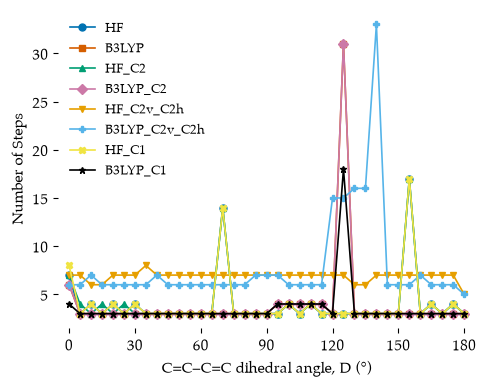

In [ ]:
#| label: plotting-steps-butadiene
#| tags: [hide-input]
#| caption: Plot of steps for each optimization in the rotational scans for butadiene


import matplotlib.pyplot as plt
from itertools import cycle

# Okabe–Ito palette: colour-blind safe and distinct in greyscale print
default_colors  = cycle(["#0072B2", "#D55E00", "#009E73", "#CC79A7",
                         "#E69F00", "#56B4E9", "#F0E442", "#000000"])
default_markers = cycle(["o", "s", "^", "D", "v", "P", "X", "*"])

# Optional: pin specific styles to specific data sets (keys must match data.keys())
colors  = {}   # e.g. {"HF/STO-3G": "#0072B2", "B3LYP/6-31G*": "#D55E00"}
markers = {}   # e.g. {"HF/STO-3G": "o",       "B3LYP/6-31G*": "s"}

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

for label, scan in data.items():    # dict.items() method returns keys and contents of keys in an iterable object
    D_list     = [point["D"] for point in scan]      # dihedral angle at each step of the scan
    steps_list = [point["steps"] for point in scan]  # optimization steps at each point of the scan

    ax.plot(D_list, steps_list,
            color=colors.get(label, next(default_colors)),
            marker=markers.get(label, next(default_markers)),
            markersize=5,
            linewidth=1.2,
            label=label,
            zorder=2)

ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("Number of Steps")
ax.set_xlim(-5, 185)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])

ax.legend(loc="best", fontsize="small", frameon=False)
# If the legend covers data, put it outside the plot instead:
# ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize="small", frameon=False)

plt.tight_layout()
plt.savefig(output_dir / "steps_plot.pdf")  # this will be a clearer image to inspect in a PDF reader
plt.show()

### Those Outliers

We do see that the **number of steps** is consistent in each run with the presence of a few **extreme outliers**. Where these outliers occur, the optimizer had **difficulty** reaching a minimum energy. Did we end up **trapped** in an **incorrect** structure? We may see errors in the energy due to **imperfect** optimization when the system encounters these issues.

Here is a list of initial observations for [](#plotting-steps-butadiene).

- The **initial optimization** used about the **same** number of **steps** in all cases. The relaxed scans then used fewer steps (except in a few outlier cases).
- Three **low-effort** `HF/6-31G` relaxed scans had **difficulty** optimizing when `D = 70` and `D = 155`. The `non-relaxed` scan **avoided** this problem **somehow**. The starting geometry that resulted from taking the result of the **previous** optimization created a problem when the **value** of `D` was **incremented**. Did we eventually find the correct structure? We will see.
- All of the **medium effort** `B3LYP-D3BJ/6-31G*` scans had **difficulty** when `D = 125`. This occured in a relaxed scan and in the non-relaxed scan. The non-relaxed scan had difficulty at `D = 115, 120, 125, 130, 135`. 
- The **non-relaxed** `HF/6-31G` ($C_{2v}$ to $C_{2h}$) had **no outliers**. I had previously observed that the **standard deviation** for the number of steps in this case is **very small** compared to all the other cases.

### Future Work

We should **repeat** the scans with outliers using the given **value** of `D` and **set** some of the other variables to slightly **different** values. If we get a lower-energy structure then we are **closer** to correct. We could also perform the scans in **reverse**, with `D` stepping from `180` to `0` and see if the **outliers** occur at different places.

Before we set ourselves **more tasks** to do, lets **check** the energies for outliers first.

## Plotting Energy

We will now **plot the energy** for each scan. [](#plotting-energy-butadiene) plots the calculated energy for each optimized geometry in the scan. You can **choose** from the **eight scans** by setting the value of `n` from 0 to 7 in the code. **Explore** and see if you notice any kinks in a plot.

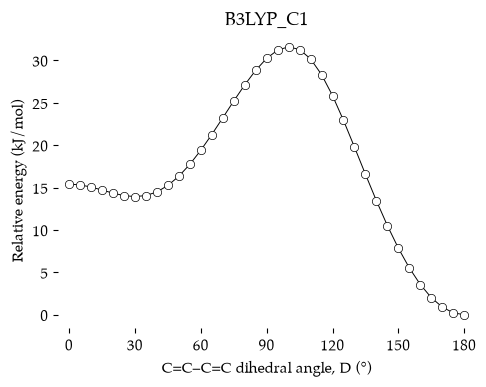

In [ ]:
#| label: plotting-energy-butadiene
#| tags: [hide-input]
#| caption: Plot of energies for rotational scan of butadiene. Data is available for four different scans and two levels of effort. Change the code to access each data set.


n = 7  # change this number from 0 to 7 to access each scan

name = list(data.keys())[n]  # get nth key in data dictionary
scan = data[name]

scan.sort(key=lambda point: point["D"])          # make sure points are in order of D
Ds = [point["D"] for point in scan]
Es = [point["E"] for point in scan]              # hartree
E_min = min(Es)
E_rel = [(E - E_min) * psi4.constants.hartree2kJmol for E in Es]       # kJ/mol relative to the lowest point


fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))

ax.plot(Ds, E_rel, color="black", linewidth=0.7, 
        marker="o", markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, 
        zorder=2)

ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("Relative energy (kJ/mol)")
ax.set_xlim(-5, 185)
ax.set_xticks([0,30,60,90,120,150,180])
ax.set_title(name)

plt.show()

Change `n` to **any value** from `0` to `7`. In all the plots, I observe a **smooth curve** with **no defects**. Perhaps I need a microscope?

## Comparing Energy Plots

One way to look for **tiny differences** is to use a **difference plot**. I will **take one** data set, use it as a **standard**, and plot the **difference** for the other data sets. I will use the $C_2$ data set as the **standard** at each level of effort. You could **change** the code to use any other data set as the standard.  I will plot the **differences** for the low-effort and the medium-effort results separately. We **cannot** directly **compare** results calculated at **different levels** of theory. **Higher** levels of theory always produce **lower** energies (the lowest energy obtained is the closest to the truth).

### Low-Effort Comparison

First I will **subtract** the array of energies for the `HF/6-31G` scan at $C_2$ symmetry (data set `HF_C2`) from the **data** for the other scans and **plot** all three. The plot in [](#plotting-energy-difference-HF-butadiene) will do that for me.

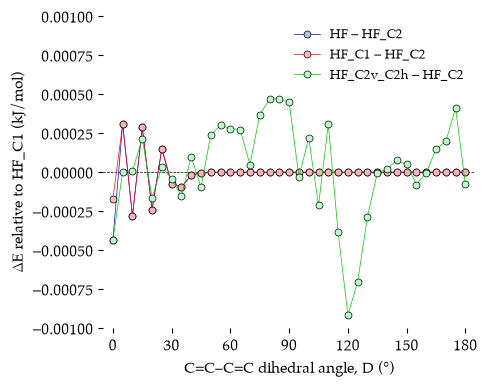

In [ ]:
#| label: plotting-energy-difference-HF-butadiene
#| tags: [hide-input]
#| caption: Plot of relative energies between the $C_2$ scan and the three others at HF/6-31G level of theory.


reference = "HF_C2"
compare   = ["HF", "HF_C1", "HF_C2v_C2h"]
fills     = ["#AEC6CF", "#FFB3BA", "#BAFFC9"]   # house pastel fills
lines     = ["#0000FF", "#FF0000", "#00CC00"]
H2KJ      = psi4.constants.hartree2kJmol

ref_scan = data[reference]                    # get data set 
ref_scan.sort(key=lambda point: point["D"])
E_ref = [point["E"] for point in ref_scan]
E_ref = np.array(E_ref)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

ax.axhline(0, color="black", linewidth=0.5, linestyle="--", zorder=1)  # zero line = same energy as HF_C1

for label, fill, line in zip(compare, fills, lines):

    scan = data[label]
    scan.sort(key=lambda point: point["D"])          # make sure points are in order of D
    Ds = [point["D"] for point in scan]
    Es = [point["E"] for point in scan]              # hartree
    Es = np.array(Es)

    dE = (Es - E_ref) * H2KJ

    ax.plot(Ds, dE,
            color=line, linewidth=0.5,
            marker="o", markersize=5,
            markerfacecolor=fill, markeredgecolor="black", markeredgewidth=0.5,
            label=f"{label} − {reference}",
            zorder=2)

ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("ΔE relative to HF_C2 (kJ/mol)")
ax.set_xlim(-5, 185)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
ax.set_ylim(-0.001,0.001)
ax.legend(loc="best", fontsize="small", frameon=False)

plt.show()

As you can see, I set the **range** of the energy difference in the plot to $\pm$0.001 kJ/mole. All the deviations are **insignificantly small**. We can make some observations, though. The  `HF_C2v_C2h` data indicates that **starting** from the **same** Z-matrix every time results in reaching the bottom of the energy well at a very slightly **different** geometry. The `HF_C1` and `HF` data start by landing at slightly different geometries compared to the `HF_C2` data, but **eventually** track with exactly the same geometries. This is because we are using the **previous** optimized geometry for each **new** optimization calculation in the **scan**. It is inevitable that we will eventually get to the **same** destination.

### Medium-Effort Comparison

Next, I will **subtract** the array of energies for the `B3LYP-D3BJ/6-31G*` scan at $C_2$ symmetry (the `B3LYP_C2` data set) from the **data** for the **other** scans and plot all three. See [](#plotting-energy-difference-B3LYP-butadiene).

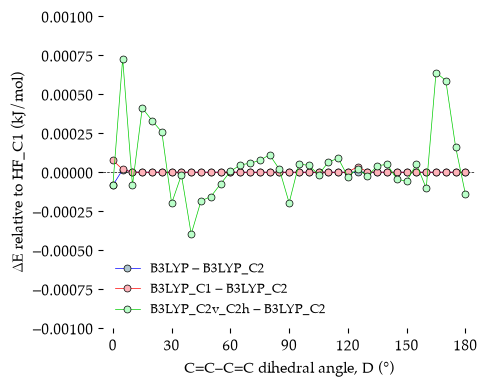

In [ ]:
#| label: plotting-energy-difference-B3LYP-butadiene
#| tags: [hide-input]
#| caption: Plot of relative energies between the $C_2$ scan and the three others at B3LYP-D3BJ/6-31G* level of theory.

reference = "B3LYP_C2"
compare   = ["B3LYP", "B3LYP_C1", "B3LYP_C2v_C2h"]
fills     = ["#AEC6CF", "#FFB3BA", "#BAFFC9"]   # house pastel fills
lines     = ["#0000FF", "#FF0000", "#00CC00"]
H2KJ      = psi4.constants.hartree2kJmol

ref_scan = data[reference]                    # get data set 
ref_scan.sort(key=lambda point: point["D"])
E_ref = [point["E"] for point in ref_scan]
E_ref = np.array(E_ref)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

ax.axhline(0, color="black", linewidth=0.5, linestyle="--", zorder=1)  # zero line = same energy as HF_C1

for label, fill, line in zip(compare, fills, lines):

    scan = data[label]
    scan.sort(key=lambda point: point["D"])          # make sure points are in order of D
    Ds = [point["D"] for point in scan]
    Es = [point["E"] for point in scan]              # hartree
    Es = np.array(Es)

    dE = (Es - E_ref) * H2KJ

    ax.plot(Ds, dE,
            color=line, linewidth=0.5,
            marker="o", markersize=5,
            markerfacecolor=fill, markeredgecolor="black", markeredgewidth=0.5,
            label=f"{label} − {reference}",
            zorder=2)

ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("ΔE relative to B3LYP_C2 (kJ/mol)")
ax.set_xlim(-5, 185)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
ax.set_ylim(-0.001,0.001)
ax.legend(loc="best", fontsize="small", frameon=False)

plt.show()

Again, the energy **differences** between the runs were **too small** to bother with. We again see more variety in the `B3LYP_C2v_C2h` scan where we **reused** the same Z-matrix as the starting geomtry in every optimization. The others were **relaxed scans** that used the result of the **previous** optimization as the **starting** point for the **next** step in the scan. We see that all three relaxed scans found the **same** geometry immediately after leaving the $C_{2v}$ geometry of the **initial** Z-matrix.

### That D = 125 Point

We observed in [](#plotting-steps-butadiene) that the B3LYP-D3BJ/6-31G* optimization **struggled** when `D = 125`. We can **zoom** into that area of the plot and see that this is the only place where the relaxed scans differed. [](#plotting-energy-difference-B3LYP-butadiene-zoomin125) shows that **two** of them agreed (`B3LYP_C2` and `B3LYP`) and **one** differed by an infinitesimal amount (`B3LYP_C1`). 


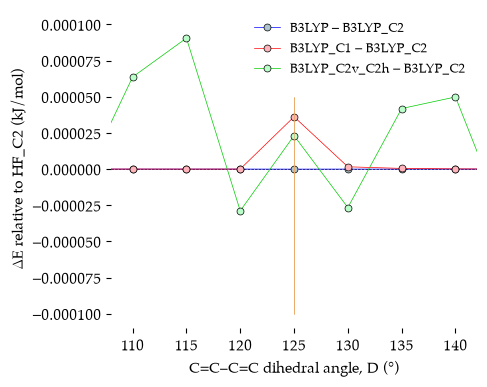

In [ ]:
#| label: plotting-energy-difference-B3LYP-butadiene-zoomin125
#| tags: [hide-input]
#| caption: Detail of plot of relative energies between the $C_2$ scan and the three others at B3LYP-D3BJ/6-31G* level of theory.


reference = "B3LYP_C2"
compare   = ["B3LYP", "B3LYP_C1", "B3LYP_C2v_C2h"]
fills     = ["#AEC6CF", "#FFB3BA", "#BAFFC9"]   # house pastel fills
lines     = ["#0000FF", "#FF0000", "#00CC00"]
H2KJ      = psi4.constants.hartree2kJmol

ref_scan = data[reference]                    # get data set 
ref_scan.sort(key=lambda point: point["D"])
E_ref = [point["E"] for point in ref_scan]
E_ref = np.array(E_ref)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

ax.axhline(0, color="black", linewidth=0.5, linestyle="--", zorder=1)  # zero line = same energy as HF_C1

for label, fill, line in zip(compare, fills, lines):

    scan = data[label]
    scan.sort(key=lambda point: point["D"])          # make sure points are in order of D
    Ds = [point["D"] for point in scan]
    Es = [point["E"] for point in scan]              # hartree
    Es = np.array(Es)

    dE = (Es - E_ref) * H2KJ

    ax.plot(Ds, dE,
            color=line, linewidth=0.5,
            marker="o", markersize=5,
            markerfacecolor=fill, markeredgecolor="black", markeredgewidth=0.5,
            label=f"{label} − {reference}",
            zorder=2)
    ax.vlines(125, -0.0001,0.00005,linewidth=0.5,color="#EBAB6A")

ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("ΔE relative to HF_C2 (kJ/mol)")
ax.set_xlim(108, 142)
ax.set_xticks([110,115,120,125,130,135,140])
ax.set_ylim(-0.00011,0.00011)
ax.legend(loc="best", fontsize="small", frameon=False)

plt.show()

## Comparing Methods

It appears that the four approaches to performing the scan all gave the same answers, within any level of precision that we care about. I will use the `HF_C2` and `B3LYB_C2` data sets going forward. These maintain $C_2$ symmetry to speed calculations but avoid the $C_{2v}$ and $C_{2h}$ symmetry traps at the start and end of the scan. 

the two methods should produce significant energy differences. I would exxpect that the higher level of theory would produce more accurate, lower energy results. Let us plot the difference in energy in each scan.

For B3LYP_C2 scan...
E diff between D = 0 and D = 180 is 15.4 kJ/mole
Barrier to rotation (D=180 to peak) is 31.6 kJ/mole
-------
For HF_C2 scan...
E diff between D = 0 and D = 180 is 14.8 kJ/mole
Barrier to rotation (D=180 to peak) is 25.8 kJ/mole
-------


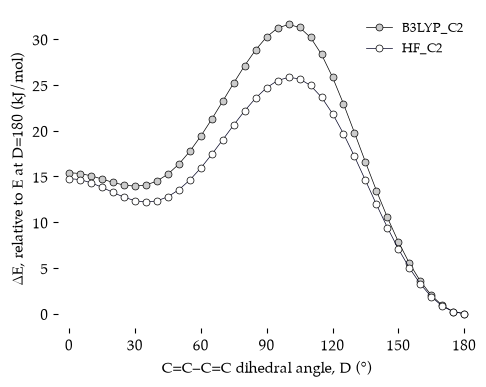

Energy difference from HF_C2 to B3LYP_C2 is -2988.8 kJ/mole


In [ ]:
#| label: plotting-energy-difference-method-butadiene
#| tags: [hide-input]
#| caption: Relative energies for rotational scan of butadiene at the HF/6-31G level and the B3LYP-D3BJ/6-31G* level.


reference = "B3LYP_C2"
compare   = ["B3LYP_C2", "HF_C2"]
fills     = ["#CCCCCC", "#FFFFFF"]   # house pastel fills
lines     = ["#000000", "#000022"]
H2KJ      = psi4.constants.hartree2kJmol

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

E180 = []
for label, fill, line in zip(compare, fills, lines):

    scan = data[label]
    scan.sort(key=lambda point: point["D"])          # make sure points are in order of D
    Ds = [point["D"] for point in scan]
    Es = np.array([point["E"] for point in scan]) * H2KJ
    Erel = Es - Es[-1]              # hartree
    E180.append(Es[-1])
    ax.plot(Ds, Erel,
            color=line, linewidth=0.5,
            marker="o", markersize=5,
            markerfacecolor=fill, markeredgecolor="black", markeredgewidth=0.5,
            label=f"{label}",
            zorder=2)
    print(f"For {label} scan...")
    print(f"E diff between D = 0 and D = 180 is {Es[0]-Es[-1]:.1f} kJ/mole")
    print(f"Barrier to rotation (D=180 to peak) is {np.max(Es)-Es[-1]:.1f} kJ/mole")
    print("-------")
ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("ΔE, relative to E at D=180 (kJ/mol)")
ax.set_xlim(-5, 185)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
#ax.set_ylim(-0.001,0.001)
ax.legend(loc="best", fontsize="small", frameon=False)

plt.show()

print(f"Energy difference from HF_C2 to B3LYP_C2 is {E180[0]-E180[1]:.1f} kJ/mole")

The **difference** in energy between the `D=180` optimization in **each scan** was calculated to be **–2989 kJ/mole**. The higher theory calculation placed the total electronic energy almost 3 megajoules/mole lower compared to the lower-effort scan.

Given the **large difference** in the answer when different methods are used, we must realize that the **relative** energy is the key information. In [](#plotting-energy-difference-method-butadiene), I have plotted the `HF_C2` and `B3LYB_C2` scans using the **difference** in energy from the lowest-energy geometry (`D = 180`). We see that the HF/6-31G and B3LYP-D3BJ/6-31G* optimizations found a very similar **difference** in energy between the two flat structures, the s-*cis* and s-*trans* butadiene (`D = 0` and `D = 180`). The **energy** of the rotational **barrier**, however, was very **different**. The B3LYP method tends to emphasize the benefits of conjugation **more** than the HF method. So the cost of breaking that conjugation is **greater** in B3LYP. Both B3LYP and HF tend to err in the energy of conjugation; one **overemphasizes** conjugation and the other **underestimates** it.

## Comparing Geometries

The **geometries** determined by the **two methods** are likely very **similar**. Lets check on this by **plotting** some structural parameters throughout the scan.

I will be using the atom numbering system of the [Z-matrix used in the rotational scan](ch4C-B-butadiene.ipynb#butadiene-zmatrix-imperfect-C2) at $C_2$ symmetry. Also, in [](#fig-zmatrix-butadiene-scan2), I reprise the structure of butadiene with the atom numbers shown.

:::{figure} images/Z-matrixButadiene2.png
:label: fig-zmatrix-butadiene-scan2
:width: 50%
:align: center
:alt: z-matrix diagram of butadiene

A diagram of the layout of the molecular geometry for building the Z-matrix. 
:::

### Bond Lengths

The double bonds will be **longer** when conjugated (`D=0, 180`) and **shorter** when not (`D = 90`). The central σ-bond should show the **opposite** trend.


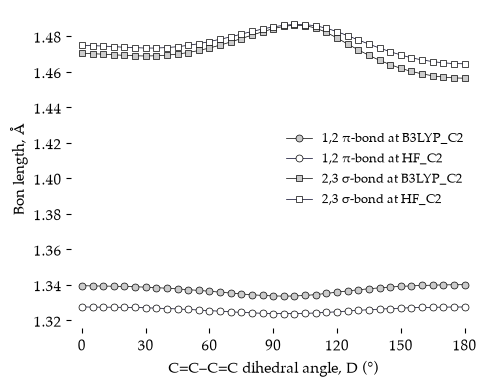

In [ ]:
#| label: plotting-bond-lengths-method-butadiene
#| tags: [hide-input]
#| caption: Bond lengths for the `1 2` and the `2 3` bonds at the HF/6-31G level and the B3LYP-D3BJ/6-31G* level.


bonds     = ["rCCterm", "rCCcent"]
descriptions = ["1,2 π-bond", "2,3 σ-bond"]
markers   = ["o","s"]
compare   = ["B3LYP_C2", "HF_C2"]
fills     = ["#CCCCCC", "#FFFFFF"]   # house pastel fills
lines     = ["#000000", "#000022"]

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

E180 = []
for bond, marker, desc in zip(bonds, markers, descriptions):
    for label, fill, line in zip(compare, fills, lines):

        scan = data[label]
        scan.sort(key=lambda point: point["D"])          # make sure points are in order of D
        Ds = [point["D"] for point in scan]
        Ls = np.array([point["var"][bond] for point in scan])
        ax.plot(Ds, Ls,
                color=line, linewidth=0.5,
                marker=marker, markersize=5,
                markerfacecolor=fill, markeredgecolor="black", markeredgewidth=0.5,
                label=f"{desc} at {label}",
                zorder=2)
ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("Bond length, Å")
ax.set_xlim(-5, 185)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
#ax.set_ylim(-0.001,0.001)
ax.legend(loc="best", fontsize="small", frameon=False)

plt.show()

We can see in [](#plotting-bond-lengths-method-butadiene) that our **prediction** is true. The **bond lengths** change slightly throughout the scan with the influence of **conjugation**. The two methods produce very similar values, The bond lengtn of the π-bond **differed** by about 0.01 Å throughout the scan, an unimportant difference.

### Bond Angles

the `1 2 3` **bond angle** represents the angle in the **carbon** backbone of the molecule. It should be 120° in a perfect $sp^2$ system. We expect that **steric effects** will push it **open** in the s-*cis* structure (`D = 0`). The `6 1 5` **angle** is the angle for the two hydrogen atoms on the **terminal** carbon atoms. This also would be 120° in a perfect world but I expect that the angle will be **compressed** in the s-*cis*


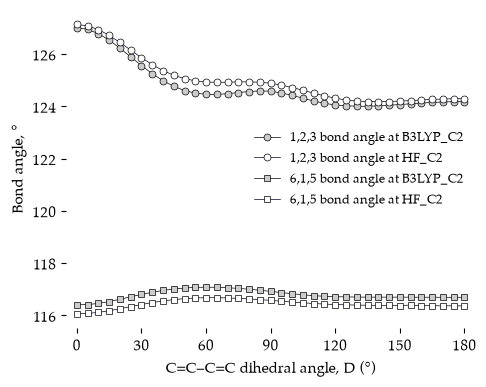

In [ ]:
#| label: plotting-bond-angles-method-butadiene
#| tags: [hide-input]
#| caption: Bond angles for the `1 2 3` and the `6 1 5` angles at the HF/6-31G level and the B3LYP-D3BJ/6-31G* level.


bonds     = ["aCCC", "aHCHterm"]
descriptions = ["1,2,3 bond angle", "6,1,5 bond angle"]
markers   = ["o","s"]
compare   = ["B3LYP_C2", "HF_C2"]
fills     = ["#CCCCCC", "#FFFFFF"]   # house pastel fills
lines     = ["#000000", "#000022"]

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

E180 = []
for bond, marker, desc in zip(bonds, markers, descriptions):
    for label, fill, line in zip(compare, fills, lines):

        scan = data[label]
        scan.sort(key=lambda point: point["D"])          # make sure points are in order of D
        Ds = [point["D"] for point in scan]
        Ls = np.array([point["var"][bond] for point in scan])
        ax.plot(Ds, Ls,
                color=line, linewidth=0.5,
                marker=marker, markersize=5,
                markerfacecolor=fill, markeredgecolor="black", markeredgewidth=0.5,
                label=f"{desc} at {label}",
                zorder=2)
ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("Bond angle, °")
ax.set_xlim(-5, 185)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
#ax.set_ylim(-0.001,0.001)
ax.legend(loc="best", fontsize="small", frameon=False)

plt.show()

The angles **agree** within half a degree between the methods. Our **prediction** that the `1 2 3` angle would be pushed open at `D = 0` compared to `D = 180` was true. The `6 1 5` bond angle was very similar at `D = 0` and `D = 180` and opened **slightly** when the molecule was not planar. 

### Conclusions

The **structures** seem to be very **similar** between the two methods. **Differences** in geometries were not enough be be considered important, although some **tiny** differences in energy could result. 

Our **expectations** for how the structure might **change** as the rotation proceeded were **confirmed**.

## Visualizing the Structures

I can use the *Py3DMol* library and some added *javascript* (courtesy of Claude) to create an interactive view of the structure at each ste of the scan. 

In [7]:
#| label: scan-viewer-butadiene
#| tags: [hide-input]
#| caption: Structure of butadiene at each point of the rotational scan. Drag the slider or press Play.

name = "B3LYP_C2"                  # any key in data, e.g. "HF_C2"

scan = data[name]
scan.sort(key=lambda point: point["D"])          # make sure points are in order of D

# Energy of each point relative to the lowest, in kJ/mol, for the label beside the slider
Es = np.array([point["E"] for point in scan])
E_rel = (Es - Es.min()) * psi4.constants.hartree2kJmol
labels = [f"D = {point['D']:5.1f}°   ΔE = {e:4.1f} kJ/mol" for point, e in zip(scan, E_rel)]

# One frame per scan point; line every frame up on atoms 1, 2 and 3 so only the far end turns
scan_xyz = ph.scan_to_xyz([point["xyz"] for point in scan], labels, align=[1, 2, 3])
ph.show_scan(scan_xyz, interactive=INTERACTIVE, interval=150)

3Dmol.js failed to load for some reason. Please check your browser console for error messages. 
 

 
 Play

The **viewer** in [](#scan-viewer-butadiene) reveals some **twists** in the bond torsions of the π-bonds. 

## Bond Torsions

Now that we have a **hint** that something is going on with the **bond torsions** we can plot them and **see** if there is useful **information** there. We will examine two torsions, the `6 1 5 2` and the `7 2 1 3` improper torsions. Both should be near 180°. 

```{note} Improper Torsions
A proper torsion is four atoms in a row, along a central connection that can rotate. The `5 1 2 3` torsion is a proper torsion along the π-bond. If you inspect the `6 1 5 2` and the `7 2 1 3` torsions, you will see that they describe whether the atoms at either end of the π-bond are in the same plane. They describe pyrimidilization or puckering at the ends of the couble bonds.
```

The `6 1 5 2` torsion describes the angle between the planes defined by each terminal hydrogen and the two carbons of the π-bond. We could also describe it as the H{sub}`exo`C{sub}`1`C{sub}`2`H{sub}`endo` torsion angle. The `7 2 1 3` torsion describes the angle between the planes defined by each terminal hydrogen and the two carbons of the π-bond. We could also describe it as the H{sub}`central`C{sub}`2`C{sub}`1`C{sub}`3` torsion angle.




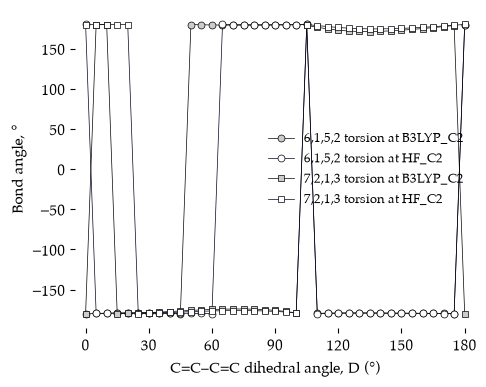

In [ ]:
#| label: plotting-bond-torsions-method-butadiene_v1
#| tags: [hide-input]
#| caption: Bond torsions for the π-bonds at the HF/6-31G level and the B3LYP-D3BJ/6-31G* level.


bonds     = ["tHCHC", "tHCCCcent"]
descriptions = ["6,1,5,2 torsion", "7,2,1,3 torsion"]
markers   = ["o","s"]
compare   = ["B3LYP_C2", "HF_C2"]
fills     = ["#CCCCCC", "#FFFFFF"]   # house pastel fills
lines     = ["#000000", "#000022"]

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

E180 = []
for bond, marker, desc in zip(bonds, markers, descriptions):
    for label, fill, line in zip(compare, fills, lines):

        scan = data[label]
        scan.sort(key=lambda point: point["D"])          # make sure points are in order of D
        Ds = [point["D"] for point in scan]
        Ts = np.array([point["var"][bond] for point in scan])
        ax.plot(Ds, Ts,
                color=line, linewidth=0.5,
                marker=marker, markersize=5,
                markerfacecolor=fill, markeredgecolor="black", markeredgewidth=0.5,
                label=f"{desc} at {label}",
                zorder=2)
ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("Bond angle, °")
ax.set_xlim(-5, 185)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
#ax.set_ylim(-0.001,0.001)
ax.legend(loc="best", fontsize="small", frameon=False)

plt.show()

Ouch! The **first** thing we see in [](#plotting-bond-torsions-method-butadiene_v1) is the **consequence** of the fact that the angles are **reported** as 179°, 180°, -179°, etc. That is why the values **flip** up and down in the plot. I need to **change** the code so that -179° becomes 181°. If we take the **modulus** as so... $$-179 \bmod 360 = 181$$ we get the lowests non-negative **remainder**, which is 181. All I had to do was add `% 360` to **one line**. The `%` is the modulo **operator** in *Python*. 

```{margin} A Note on Python
Sorry for the *Python* lesson; I wrote that for myself. It took me an hour to figure out what to do and **I don't want to forget**. (In the end, it was not me who figured it out. I asked Claude and it suggests just five ASCII characters to solve my problem. I felt humiliated. In my defence, when was the last time you though about modulus?)
```

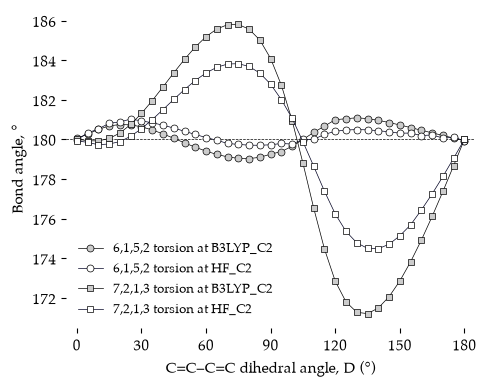

In [30]:
#| label: plotting-bond-torsions-method-butadiene_v2
#| tags: [hide-input]
#| caption: Bond torsions for the π-bonds at the HF/6-31G level and the B3LYP-D3BJ/6-31G* level.

#
bonds     = ["tHCHC", "tHCCCcent",]
descriptions = ["6,1,5,2 torsion", "7,2,1,3 torsion",]
markers   = ["o","s",]
compare   = ["B3LYP_C2", "HF_C2"]
fills     = ["#CCCCCC", "#FFFFFF"]   # house pastel fills
lines     = ["#000000", "#000022"]

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

E180 = []
for bond, marker, desc in zip(bonds, markers, descriptions):
    for label, fill, line in zip(compare, fills, lines):

        scan = data[label]
        scan.sort(key=lambda point: point["D"])          # make sure points are in order of D
        Ds = [point["D"] for point in scan]
        # The % 360 is a modulo operator giving mod 360. This makes -179 into 181
        Ts = np.array([point["var"][bond] for point in scan]) % 360
        ax.plot(Ds, Ts,
                color=line, linewidth=0.5,
                marker=marker, markersize=5,
                markerfacecolor=fill, markeredgecolor="black", markeredgewidth=0.5,
                label=f"{desc} at {label}",
                zorder=2)
ax.hlines(180,-5,185, linestyles="--", linewidths = 0.5, zorder=0)
ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("Bond angle, °")
ax.set_xlim(-5, 185)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
#ax.set_ylim(-0.001,0.001)
ax.legend(loc="best", fontsize="small", frameon=False)

plt.show()

In [](#plotting-bond-torsions-method-butadiene_v2) we see a lot going on. The **internal** carbon atoms are **puckering** (becomine slightly pyramidal) as the *p*-orbital of each sp{sup}`2` carbon tilts slightly to try to keep as much conjugation across the central C–C σ-bond as possible. The effect disappears at `D = 0` and `D = 180`, where the molecule is flat and conjugation is greatest. It also vanishes near `D ≈ 100`, where conjugation is close to fully broken and tilting either way gains nothing. The effect is much smaller at the terminal carbon atoms. The internal carbon atoms are the ones that connect via conjugation with their partner across the C–C σ-bond, and their *p*-orbitals are more involved in defining the conjugation connection.

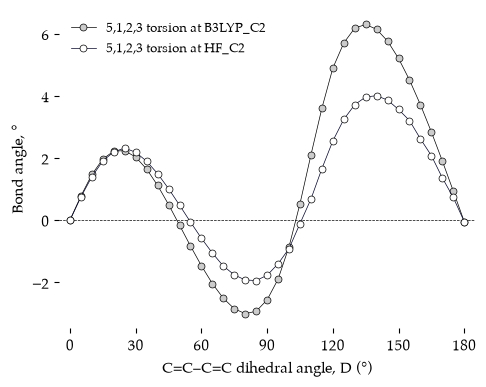

In [28]:
#| label: plotting-bond-torsions-method-butadiene_v3
#| tags: [hide-input]
#| caption: Bond torsions for the π-bonds at the HF/6-31G level and the B3LYP-D3BJ/6-31G* level.

#
bonds     = ["tHCCCendo"]
descriptions = ["5,1,2,3 torsion"]
markers   = ["o",]
compare   = ["B3LYP_C2", "HF_C2"]
fills     = ["#CCCCCC", "#FFFFFF"]   # house pastel fills
lines     = ["#000000", "#000022"]

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

E180 = []
for bond, marker, desc in zip(bonds, markers, descriptions):
    for label, fill, line in zip(compare, fills, lines):

        scan = data[label]
        scan.sort(key=lambda point: point["D"])          # make sure points are in order of D
        Ds = [point["D"] for point in scan]
        # The % 360 is a modulo operator giving mod 360. This makes -179 into 181
        Ts = np.array([point["var"][bond] for point in scan])
        ax.plot(Ds, Ts,
                color=line, linewidth=0.5,
                marker=marker, markersize=5,
                markerfacecolor=fill, markeredgecolor="black", markeredgewidth=0.5,
                label=f"{desc} at {label}",
                zorder=2)

ax.hlines(0,-5,185, linestyles="--", linewidths = 0.5, zorder=0)
ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("Bond angle, °")
ax.set_xlim(-5, 185)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
#ax.set_ylim(-0.001,0.001)
ax.legend(loc="best", fontsize="small", frameon=False)

plt.show()

In [](#plotting-bond-torsions-method-butadiene_v3) we see a similar set of excursions for the `5 1 2 3` torsion,which defines the twist of the end C-H at the terminal end of the π-bond relative to the carbon chain. It is the H{sub}`endo`C{sub}`1`C{sub}`2`C{sub}`3` angle.

What [](#plotting-bond-torsions-method-butadiene_v2) and [](#plotting-bond-torsions-method-butadiene_v3) reveal to me is that the terminal end of the π-bond remians mostly flat (the `6 1 5 2` improper torsion) and the interior end puckers (the `7 2 1 3` improper torsion). the `5 1 2 3` torsion is the result of the terminal end relative to the puckering internal end of the π-bond. The π-bond does indeed remain mostly flat. The pyrimidalization of the central carbon atom is what is being shown here. The lesser puckering of the terminal carbon matches and cancels out this `5 1 2 3` torsion angle when `D ≈ 50`. That is geometry in action. The better description of distorsion along the π-bond in this rotational scan are the the `6 1 5 2` and `7 2 1 3` improper torsions

### Conclusions

I think the better way to observe the structural changes in the π-bond is to use the *Py3DMol* viewer in [](#scan-viewer-butadiene). However, the plots in [](#plotting-bond-torsions-method-butadiene_v2) and [](#plotting-bond-torsions-method-butadiene_v3) show substantial deformation at the central carbons of the butadiene and the rotation takes place. Also, the difference between the HF/6-31G and the B3LYP-D3BJ/6-31G* methods seems to be significant in determining the geometry of these bond torsions. We know that B3LYP places a higher emphasis on conjugation, so it is no surprise that the optimization is affected by conjugation when that method is used.

## What's Next?

How much does the difference in geometries affect the energy. We should use the geometry at each point in the scan and calculate the energy at the same level of theory. We know the locations of minima and maxima in the scan to a precision of 5°. We can locate a minimum exactly by just using an unconstrained optimization, like we did [previously](ch4C-A-simple_butadiene.ipynb#its-your-turn-butadiene). But what about the maxima? We will need to use the techniques of locating transition states. Is the mid-point of a bond rotation a transition state? Sounds like there is something to talk about there.

```{warning} AI Statement
:class: dropdown
Most of this page is **my own writing**: the observations, the conclusions and most of the code that loads and plots the data. Claude (Anthropic), used through Claude Code, **contributed** in several ways at my request. It **suggested** the colours, markers and legend for the plot of optimization steps and the layout of the energy-difference plots, which I adapted. It **wrote** the `scan_to_xyz()` and `show_scan()` functions in `psi4_helpers.py` and the code for the interactive viewer in [](#scan-viewer-butadiene). It suggested `% 360` to keep the torsion angles in one continuous range. My explanations of why B3LYP favours conjugation more than HF and why the central carbon atoms pucker during the rotation grew out of **discussions** with Claude, which checked them against the scan data. The paragraph explaining the puckering is my draft as **revised** by Claude. The setup cell was **adapted** from code **generated** by Claude for the [main butadiene page](ch4C-B-butadiene.ipynb). I selected, edited and **checked** all content.
```